Background and Problem Statement

TagPro is a free-to-play online 2-D capture the flag game in which players roll around a tiled map as paint-filled balls. Typically, the matches are played 4v4 with two players on each team on defense and the other two players on offense. While it can be a fun casual game, there is a staunch competitive community centered the game as well, not unlike the competitive scene around SSB Melee. Several regions (NA, EU, OCE) have professional leagues (MLTP, ELTP, OLTP respectively) where the best of the best battle it out to see who reigns supreme. There is a lot of raw data collected and recorded from each of these competitive matches, which are then reported either as is or used to construct more complex statistics. Going another step further, those statistics are then used to judge player performance, both directly by examining the leaders in each category and also by using comparison metrics that lump together several other statistics and weighting them appropriately.

This begs the question: "How do we choose the subcomponents of the player comparison metric in a reasonable manner, and subsequently weight them appropriately?" One reasonable approach to gathering information to this end is to use supervised learning algorithms to try to predict whether a player had a winning season based on their stats. We could define a winning season as having a positive cap differential; that is, the player's team scored more caps than they allowed their opponents to score against them. Figuring out which statistics are the most important for winning is crucial for players looking to improve their game, for general managers to decide which players they want to draft to their team, and for award voters to decide which players helped their teams the most.

We will look at data from the games of North American pro league, MLTP, spanning over two dozen seasons of matches. The data for each individual season is stored separately on a site called TagPro League, or TPL for short. We will need to scrape the raw data for each season and amalgamate everything, along with doing some non-trivial cleaning and preprocessing work.

[1] TagPro League. Available at: https://www.tagproleague.com/MLTP/stats (Accessed: April 7, 2023). 

A First Look at the Data

Let's examine the data we scraped from a single season of MLTP to get a better understanding of the underlying data structure and develop a plan for curating our final dataset.

In [22]:
import pandas as pd
import numpy as np
import os
import warnings

# warnings.filterwarnings('ignore', category=DeprecationWarning)
df = pd.read_csv('C:\\Users\\jshap\\OneDrive\\Desktop\\Stats\\MLTP_S10_majors_cumulative.tsv', delimiter = '\t', engine = 'python')
print(df)

           player team  score  minutes  pm  tags  pops  grabs  drops  hold  \
0         Altiger  NaN   1462      360   9   357   551    507    459  4078   
1      Blue Dream  NaN    143       40  -5    34    76     67     60   469   
2    Death Pickle  NaN   1579      400 -16   604   310    182    174  1461   
3         BigBird  NaN   1680      400  -4   550   284    170    158  1156   
4           Vials  NaN   1295      400 -16   286   645    594    542  4400   
..            ...  ...    ...      ...  ..   ...   ...    ...    ...   ...   
130       #Frozen  NaN     77       30 -19    31    66     57     54   227   
131       DUBSTEP  NaN     91       40 -28    28   102     83     77   353   
132     alchemist  NaN    105       40 -28    46    45     23     22   116   
133        Shabba  NaN     82       40 -28    29    74     60     57   276   
134  fenix funk 5  NaN    121       40 -28    59    53     26     26    82   

     ...  goodhandoff  goregrab  coregrab  gohandoff  cohandoff

We can see that there is no column to denote which season the data is from, so we will need to add that information into the master dataset as we weld the individual datasets together. By consulting with our Subject Matter Expert, we are also aware that there is an important shift that occurs starting in Season 20. Prior to that, most of the matches were played on teams' home servers, while in S20 and onwards all teams played on the Dallas-based server, resulting in much higher average ping for most players. To capture this critical rule change, we will also append a binary variable that tracks whether the season was played on Dallas or not.  

Building the Master Dataset

In [23]:
# Define the directory containing the TSV files
directory = 'C:\\Users\\jshap\\OneDrive\\Desktop\\Stats\\'

# Get a list of all TSV files in the directory
tsv_files = [os.path.join(directory, file) for file in os.listdir(directory) if file.endswith('.tsv')]

# Initialize an empty DataFrame to hold the data
MLTP_master_stats = pd.DataFrame()

# Loop over each TSV file and load it into a DataFrame
for i, location in enumerate(tsv_files):
    temp = pd.read_csv(location, sep='\t', header=0, na_values=[''], low_memory=False)
    season = i + 10
    Dallas = 0
    
    if season >= 20:
        Dallas = 1
    
    temp['Dallas'] = Dallas        
    temp['season'] = season
    MLTP_master_stats = MLTP_master_stats.append(temp, ignore_index=True)

# Convert necessary columns to factors
MLTP_master_stats['season'] = pd.Categorical(MLTP_master_stats['season'])
MLTP_master_stats['Dallas'] = pd.Categorical(MLTP_master_stats['Dallas'])

#Add Kill/Death Ratio
MLTP_master_stats['kdr'] = MLTP_master_stats['tags'] / MLTP_master_stats['pops']

# Print the resulting DataFrame
print(MLTP_master_stats)
size = MLTP_master_stats.shape

            player team  score  minutes  pm  tags  pops  grabs  drops  hold  \
0          Altiger  NaN   1462      360   9   357   551    507    459  4078   
1       Blue Dream  NaN    143       40  -5    34    76     67     60   469   
2     Death Pickle  NaN   1579      400 -16   604   310    182    174  1461   
3          BigBird  NaN   1680      400  -4   550   284    170    158  1156   
4            Vials  NaN   1295      400 -16   286   645    594    542  4400   
...            ...  ...    ...      ...  ..   ...   ...    ...    ...   ...   
1307          Nati  TRT    159       50  10    65    50     40     39   186   
1308           bbb  ROJ    217       50   6    72    50     35     32   331   
1309          EIsa  NaN    165       50   3    34    86     83     74   472   
1310   TheEpicBlob  TGB    201       70   4    70    62     30     29   114   
1311       Pie Cat  NaN    196       50   8    54    69     63     54   426   

      ...  gohandoff  cohandoff  retinbase  quickre

C:\Users\jshap\AppData\Local\Temp\ipykernel_12308\292625779.py:21: FutureWarning:

The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.

C:\Users\jshap\AppData\Local\Temp\ipykernel_12308\292625779.py:21: FutureWarning:

The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.

C:\Users\jshap\AppData\Local\Temp\ipykernel_12308\292625779.py:21: FutureWarning:

The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.

C:\Users\jshap\AppData\Local\Temp\ipykernel_12308\292625779.py:21: FutureWarning:

The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.

C:\Users\jshap\AppData\Local\Temp\ipykernel_12308\292625779.py:21: FutureWarning:

The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat 

Now we have our full master dataset in all its glory! Let's investigate its properties a bit before getting ahead of ourselves with the data cleaning steps. We can see that we have 1312 observations, each containing 28 innate features and the three extra that we tacked on while creating the master dataset for a total of 31 features. The features 'Player' and 'team' are strings, 'Dallas' and 'season' are categorical features, 'Unnamed: 27' is a column full of all NaN values, and the other 26 features are various numeric integer statistical measures directly captured from the gameplay or calculated from directly captured data (such as Kill/Death Ratio).

Data Cleaning

Let's programmatically check for missing values in each column for starters, in case the summary earlier didn't get the full picture:

In [24]:
for col in MLTP_master_stats.columns:
    temp = MLTP_master_stats[col].isna().sum()
    print(f"Missing values in feature '{col}': {temp} out of {size[0]}, or {round(100 * temp / size[0], 1)}% missing")

Missing values in feature 'player': 0 out of 1312, or 0.0% missing
Missing values in feature 'team': 1031 out of 1312, or 78.6% missing
Missing values in feature 'score': 0 out of 1312, or 0.0% missing
Missing values in feature 'minutes': 0 out of 1312, or 0.0% missing
Missing values in feature 'pm': 0 out of 1312, or 0.0% missing
Missing values in feature 'tags': 0 out of 1312, or 0.0% missing
Missing values in feature 'pops': 0 out of 1312, or 0.0% missing
Missing values in feature 'grabs': 0 out of 1312, or 0.0% missing
Missing values in feature 'drops': 0 out of 1312, or 0.0% missing
Missing values in feature 'hold': 0 out of 1312, or 0.0% missing
Missing values in feature 'captures': 0 out of 1312, or 0.0% missing
Missing values in feature 'prevent': 0 out of 1312, or 0.0% missing
Missing values in feature 'returns': 0 out of 1312, or 0.0% missing
Missing values in feature 'pups': 0 out of 1312, or 0.0% missing
Missing values in feature 'pupscomp': 0 out of 1312, or 0.0% missing
M

We can see that 'team' is missing almost 80% of its values, while 'Unnamed: 27' is entirely empty. There is no realistic way to impute values for either of these columns, so we will simply just drop them from the dataset entirely. Fortunately, almost every other column besides those two has exactly 0 missing values, so we are spared the effort of needing to impute anything at all. Note that there are a few missing values in the 'kdr' column, but we also know that 'kdr' is calculated directly from 'tags' divided by 'pops' and there is no missing data in either of those columns. What's going on here? A few of the players with a very low amount of minutes have 0 pops, which causes their KDR to became NaN due to a division by zero error. We will circle back around to this after we filter out the players with too few minutes and we should see the missing values vanish.

In [25]:
MLTP_master_stats = MLTP_master_stats.drop(['team', 'Unnamed: 27'], axis = 1)
#print(MLTP_master_stats)

Another thing of importance to note from consultation with our SME is that different seasons had different numbers of weeks played, and some of the more recent seasons even had a different number of games and therefore minutes played each week. For a long time, the standard season length was 10 weeks with two 20 minute games a week for a total of 400 minutes played in a season. Season lengths started dropping down to around 7 weeks over time, and then in the past few seasons, the game format shifted from two 20 minute games to five 10 minute games a week. To handle this, we should temporally normalize all of these aggregation stats as per minute statistics instead.

In [26]:
MLTP_master_stats.columns

Index(['player', 'score', 'minutes', 'pm', 'tags', 'pops', 'grabs', 'drops',
       'hold', 'captures', 'prevent', 'returns', 'pups', 'pupscomp',
       'flaccids', 'longholds', 'handoff', 'goodhandoff', 'goregrab',
       'coregrab', 'gohandoff', 'cohandoff', 'retinbase', 'quickret', 'saves',
       'holdagainst', 'Dallas', 'season', 'kdr'],
      dtype='object')

In [27]:
#Aggregation stats to be temporally normalized
agg_cols = ['score', 'pm', 'tags', 'pops', 'grabs', 'drops',
       'hold', 'captures', 'prevent', 'returns', 'pups', 'pupscomp',
       'flaccids', 'longholds', 'handoff', 'goodhandoff', 'goregrab',
       'coregrab', 'gohandoff', 'cohandoff', 'retinbase', 'quickret', 'saves',
       'holdagainst']

# Divide the columns by minutes played
MLTP_master_stats[agg_cols] = MLTP_master_stats[agg_cols].div(MLTP_master_stats['minutes'], axis = 0)

# Define a list of new column names
pm_cols = ['scorepm', 'successpm', 'tpm', 'poppm', 'gpm', 'dropspm',
       'hpm', 'cpm', 'ppm', 'rpm', 'puppm', 'pupscomppm',
       'flaccidspm', 'longholdspm', 'handoffpm', 'goodhandoffpm', 'goregrabpm',
       'coregrabpm', 'gohandoffpm', 'cohandoffpm', 'retinbasepm', 'quickretpm', 'savespm',
       'holdagainstpm']

# Create a dictionary of column name mappings
col_mapping = dict(zip(agg_cols, pm_cols))

# Rename the columns using the dictionary of column name mappings
MLTP_master_stats.rename(columns = col_mapping, inplace = True)

# Print the updated DataFrame
print(MLTP_master_stats)

            player   scorepm  minutes  successpm       tpm     poppm  \
0          Altiger  4.061111      360   0.025000  0.991667  1.530556   
1       Blue Dream  3.575000       40  -0.125000  0.850000  1.900000   
2     Death Pickle  3.947500      400  -0.040000  1.510000  0.775000   
3          BigBird  4.200000      400  -0.010000  1.375000  0.710000   
4            Vials  3.237500      400  -0.040000  0.715000  1.612500   
...            ...       ...      ...        ...       ...       ...   
1307          Nati  3.180000       50   0.200000  1.300000  1.000000   
1308           bbb  4.340000       50   0.120000  1.440000  1.000000   
1309          EIsa  3.300000       50   0.060000  0.680000  1.720000   
1310   TheEpicBlob  2.871429       70   0.057143  1.000000  0.885714   
1311       Pie Cat  3.920000       50   0.160000  1.080000  1.380000   

           gpm   dropspm        hpm       cpm  ...  coregrabpm  gohandoffpm  \
0     1.408333  1.275000  11.327778  0.100000  ...    0.

On top of this, starting players will miss games and there will also be substitute players from the lower leagues filling in occasionally. We would like to exclude players that don't have many minutes played in a season, as they are likely either a minors player subbing or a majors player that got dropped for underperforming, either way not strong enough to be considered a majors level player. Additionally, a low number of minutes would make it more likely that their stats would be a huge outlier and throw off the model. Based on the recommendation of our SME, we will set this threshold as < 100 minutes played.  

In [28]:
MLTP_master_stats.drop(MLTP_master_stats[MLTP_master_stats['minutes'] < 100].index, inplace = True)
print(MLTP_master_stats)

            player   scorepm  minutes  successpm       tpm     poppm  \
0          Altiger  4.061111      360   0.025000  0.991667  1.530556   
2     Death Pickle  3.947500      400  -0.040000  1.510000  0.775000   
3          BigBird  4.200000      400  -0.010000  1.375000  0.710000   
4            Vials  3.237500      400  -0.040000  0.715000  1.612500   
5          Mr.Gone  3.925000      400  -0.040000  1.392500  1.027500   
...            ...       ...      ...        ...       ...       ...   
1301    BoldRoller  3.750000      268   0.070896  0.917910  1.727612   
1303         Prime  3.370000      200   0.100000  0.980000  1.150000   
1304         titan  3.070000      100  -0.040000  0.840000  1.760000   
1305  flaccid trip  3.887097      248  -0.129032  1.221774  1.120968   
1306            Ty  3.613445      238   0.096639  0.894958  1.218487   

           gpm   dropspm        hpm       cpm  ...  coregrabpm  gohandoffpm  \
0     1.408333  1.275000  11.327778  0.100000  ...    0.

In [29]:
for col in MLTP_master_stats.columns:
    temp = MLTP_master_stats[col].isna().sum()
    print(f"Missing values in feature '{col}': {temp} out of {size[0]}, or {round(100 * temp / size[0], 1)}% missing")

Missing values in feature 'player': 0 out of 1312, or 0.0% missing
Missing values in feature 'scorepm': 0 out of 1312, or 0.0% missing
Missing values in feature 'minutes': 0 out of 1312, or 0.0% missing
Missing values in feature 'successpm': 0 out of 1312, or 0.0% missing
Missing values in feature 'tpm': 0 out of 1312, or 0.0% missing
Missing values in feature 'poppm': 0 out of 1312, or 0.0% missing
Missing values in feature 'gpm': 0 out of 1312, or 0.0% missing
Missing values in feature 'dropspm': 0 out of 1312, or 0.0% missing
Missing values in feature 'hpm': 0 out of 1312, or 0.0% missing
Missing values in feature 'cpm': 0 out of 1312, or 0.0% missing
Missing values in feature 'ppm': 0 out of 1312, or 0.0% missing
Missing values in feature 'rpm': 0 out of 1312, or 0.0% missing
Missing values in feature 'puppm': 0 out of 1312, or 0.0% missing
Missing values in feature 'pupscomppm': 0 out of 1312, or 0.0% missing
Missing values in feature 'flaccidspm': 0 out of 1312, or 0.0% missing
M

Now that all of our cleaning and filtering has been completed, we can see that the 'kdr' column no longer has any missing values, so impution will not be necessary. Now we're ready to proceed on to the EDA phase. 

Exploratory Data Analysis

Now that our dataset is ready to go, we can start to investigate the data more thoroughly. Let's take a look at some of the statistics that are considered the most important by the MLTP community according to our SME. For defenders, the five most important stats are usually considered to be Tags, Returns, Prevent, Kill/Death Ratio, and Powerups. For offenders, the top five are generally believed to be Captures, Grabs, Hold, Scoring Percentage, and Powerups.

We will start off looking at Prevent/Min vs Capture Differential/Min with the size of the data points representing 'score/min'. Score is the overall player evaluation statistic that is baked into the game by the developer, which is ignored entirely by the competitive community.

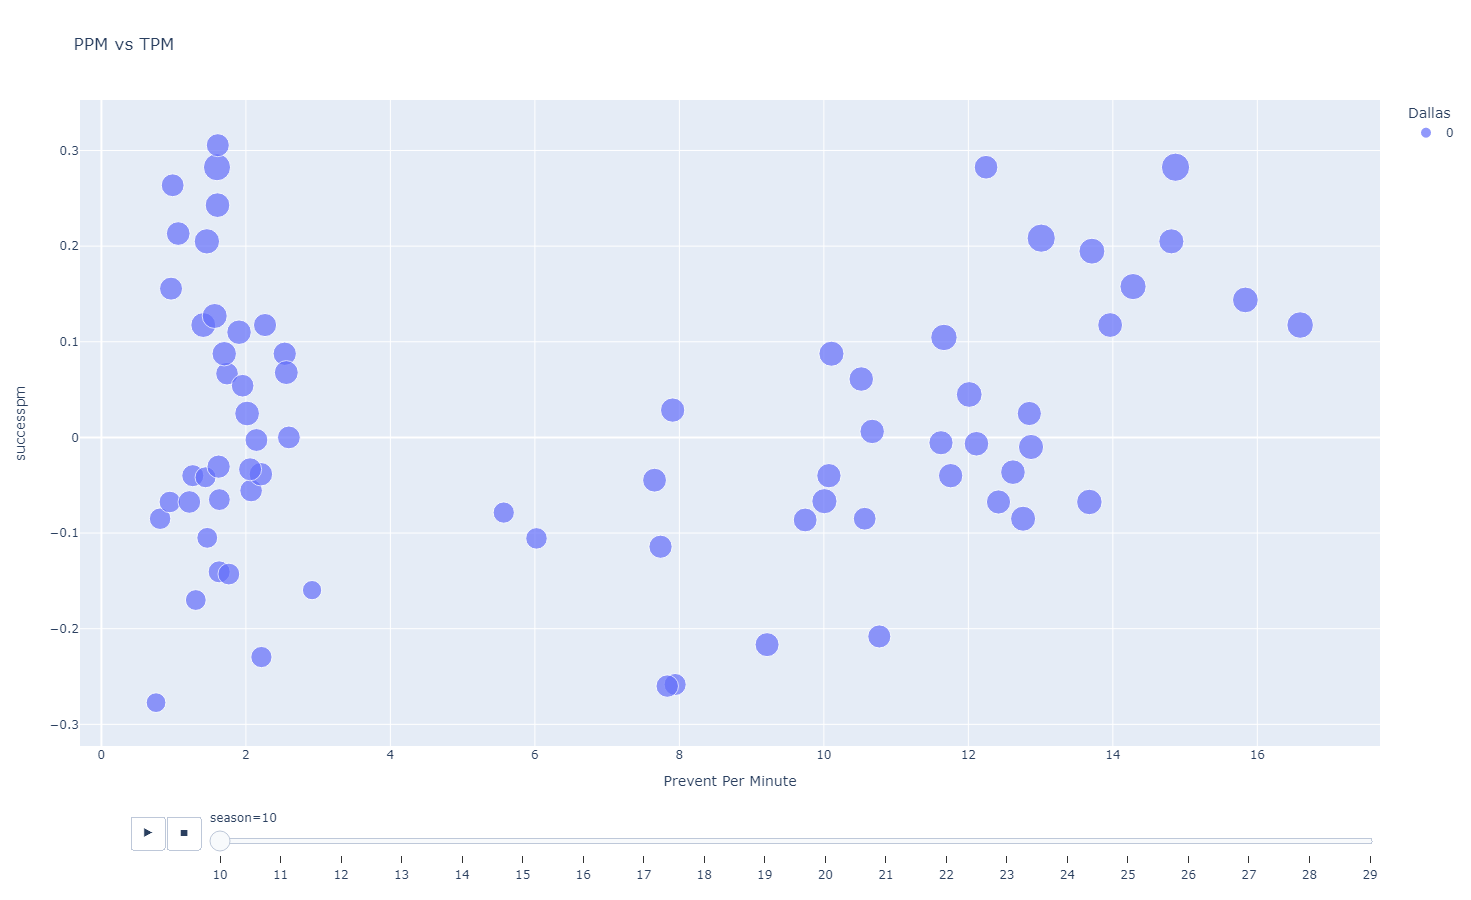

In [30]:
import plotly.express as px

ppm_all = px.scatter(MLTP_master_stats, x="ppm", y="successpm",
size="scorepm", color="Dallas", animation_frame="season",
hover_data=["player"],
labels={'ppm': 'Prevent Per Minute', 'tpm': 'Tags Per Minute'},
title='PPM vs TPM')

ppm_all.update_layout(scene=dict(xaxis=dict(title='Prevent Per Minute'),
yaxis=dict(title='Tags Per Minute')), height = 900)
ppm_all.show()

Looking at the plot for Season 10, which is the default plot that is displayed, we should immediately notice something strange about the shape of the data. There are two main clusters of data points, one of which forms a vertical cluster on the low end of the x axis, indicating that those players' success seems to be independent of their prevent per minute (PPM), while the other cluster of points follows more of a f(x) = cx shape with a weak to moderate positive correlation between PPM and success per minute. Why is this? Players that are offenders will almost always have very low prevent numbers, as they spend very little time in game defending their own flag while attending to their offense duties. Let's look at Hold, a statistic primarily earned by offenders, and confirm that we have a similar pattern.

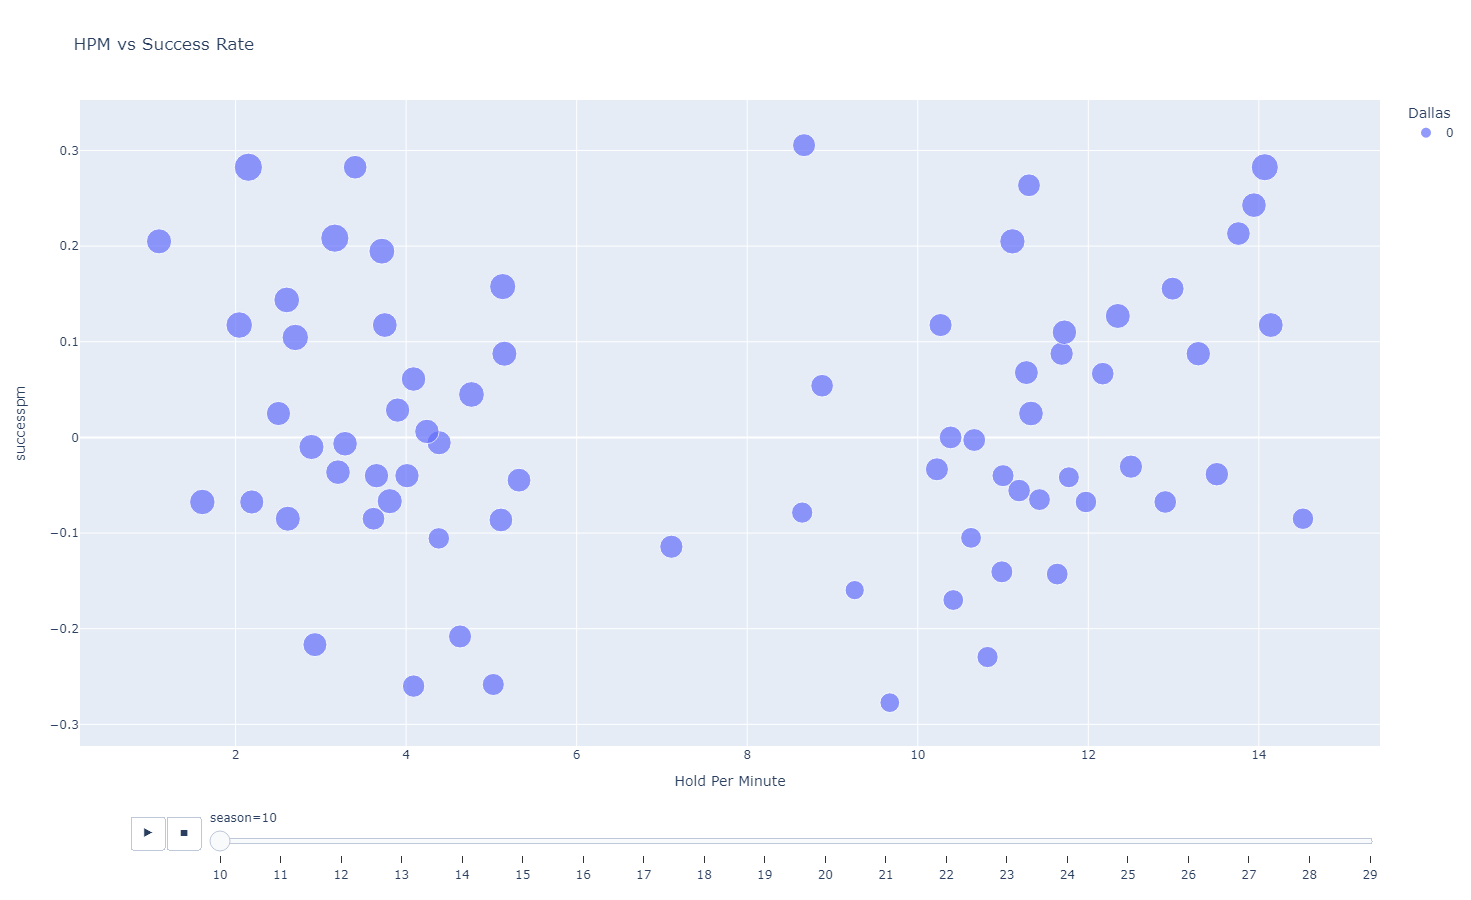

In [31]:
hpm_all = px.scatter(MLTP_master_stats, x="hpm", y="successpm",
size="scorepm", color="Dallas", animation_frame="season",
hover_data=["player"],
labels={'hpm': 'Hold Per Minute', 'tpm': 'Tags Per Minute'},
title='HPM vs Success Rate')

hpm_all.update_layout(scene=dict(xaxis=dict(title='Hold Per Minute'),
yaxis=dict(title='Tags Per Minute')), height = 900)
hpm_all.show()

For Season 10 through 15, we again see this phenomenon of two main clusters of points, with the low values of hold having no correlation (the defenders) and the higher values of hold have a weak positive correlation (the offenders). Interestingly, there appears to be a fairly evenly spread, single cloud of points, with no indication of any correlation between hold and success for Season 16 onwards, which seems indicative that hold has not been an important statistic to consider for quite some time. This contradicts the widely held community belief that hold is one of the most important statistics to focus on for an offender.

Setting aside this shocking revelation about the importance of Hold for a moment, it becomes clear to us that we need to add some more information to the feature space. First, we need some way to differentiate between offenders and defenders; a successful model will certainly need to treat those as two separate populations if there are multiple features that are only predictive for one of the groups but not the other. While we're at it, we might as well create a binary attribute 'winner' that is 1 if the player has a positive cap differential and 0 otherwise. We will need this response variable both for training and testing the model.

Unfortunately, we don't have access to information on which position each player is playing, and some players will play a mix of both roles throughout a season. The best we can do is assign 'defender' to a player with higher prevent than hold and 'offender' to a player with higher hold than prevent. Irritatingly, sklearn does not handle categorical strings in a graceful manner, so for ease of model building we will just use a '0' for offense and a '1' for defense. 

In [32]:
MLTP_master_stats['position'] = np.where(MLTP_master_stats['ppm'] > MLTP_master_stats['hpm'], 1, 0)
MLTP_master_stats['position'] = MLTP_master_stats['position'].astype('category')

MLTP_master_stats['winner'] = np.where(MLTP_master_stats['successpm'] > 0, 1, 0)
MLTP_master_stats['winner'] = MLTP_master_stats['winner'].astype('category')

MLTP_master_stats

,player,scorepm,minutes,successpm,tpm,poppm,gpm,dropspm,hpm,cpm,...,cohandoffpm,retinbasepm,quickretpm,savespm,holdagainstpm,Dallas,season,kdr,position,winner
0,Altiger,4.061111,360,0.025000,0.991667,1.530556,1.408333,1.275000,11.327778,0.100000,...,0.008333,0.133333,0.111111,0.013889,30.463889,0,10,0.647913,0,1
2,Death Pickle,3.947500,400,-0.040000,1.510000,0.775000,0.455000,0.435000,3.652500,0.017500,...,0.000000,0.472500,0.412500,0.007500,31.052500,0,10,1.948387,1,0
3,BigBird,4.200000,400,-0.010000,1.375000,0.710000,0.425000,0.395000,2.890000,0.015000,...,0.000000,0.405000,0.365000,0.005000,30.040000,0,10,1.936620,1,0
4,Vials,3.237500,400,-0.040000,0.715000,1.612500,1.485000,1.355000,11.000000,0.102500,...,0.010000,0.097500,0.085000,0.007500,31.052500,0,10,0.443411,0,0
5,Mr.Gone,3.925000,400,-0.040000,1.392500,1.027500,0.565000,0.530000,4.010000,0.032500,...,0.002500,0.432500,0.335000,0.007500,31.052500,0,10,1.355231,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1301,BoldRoller,3.750000,268,0.070896,0.917910,1.727612,1.473881,1.339552,10.167910,0.126866,...,0.011194,0.205224,0.227612,0.003731,25.104478,1,29,0.531317,0,1
1303,Prime,3.370000,200,0.100000,0.980000,1.150000,0.775000,0.715000,3.665000,0.050000,...,0.000000,0.290000,0.270000,0.010000,27.620000,1,29,0.852174,1,1
1304,titan,3.070000,100,-0.040000,0.840000,1.760000,1.300000,1.180000,8.150000,0.110000,...,0.000000,0.200000,0.150000,0.020000,28.550000,1,29,0.477273,0,0
1305,flaccid trip,3.887097,248,-0.129032,1.221774,1.120968,0.931452,0.842742,7.483871,0.072581,...,0.000000,0.395161,0.338710,0.004032,26.661290,1,29,1.089928,1,0


Next, let's check the correlation strength between the features to see if there are any highly correlated variables.

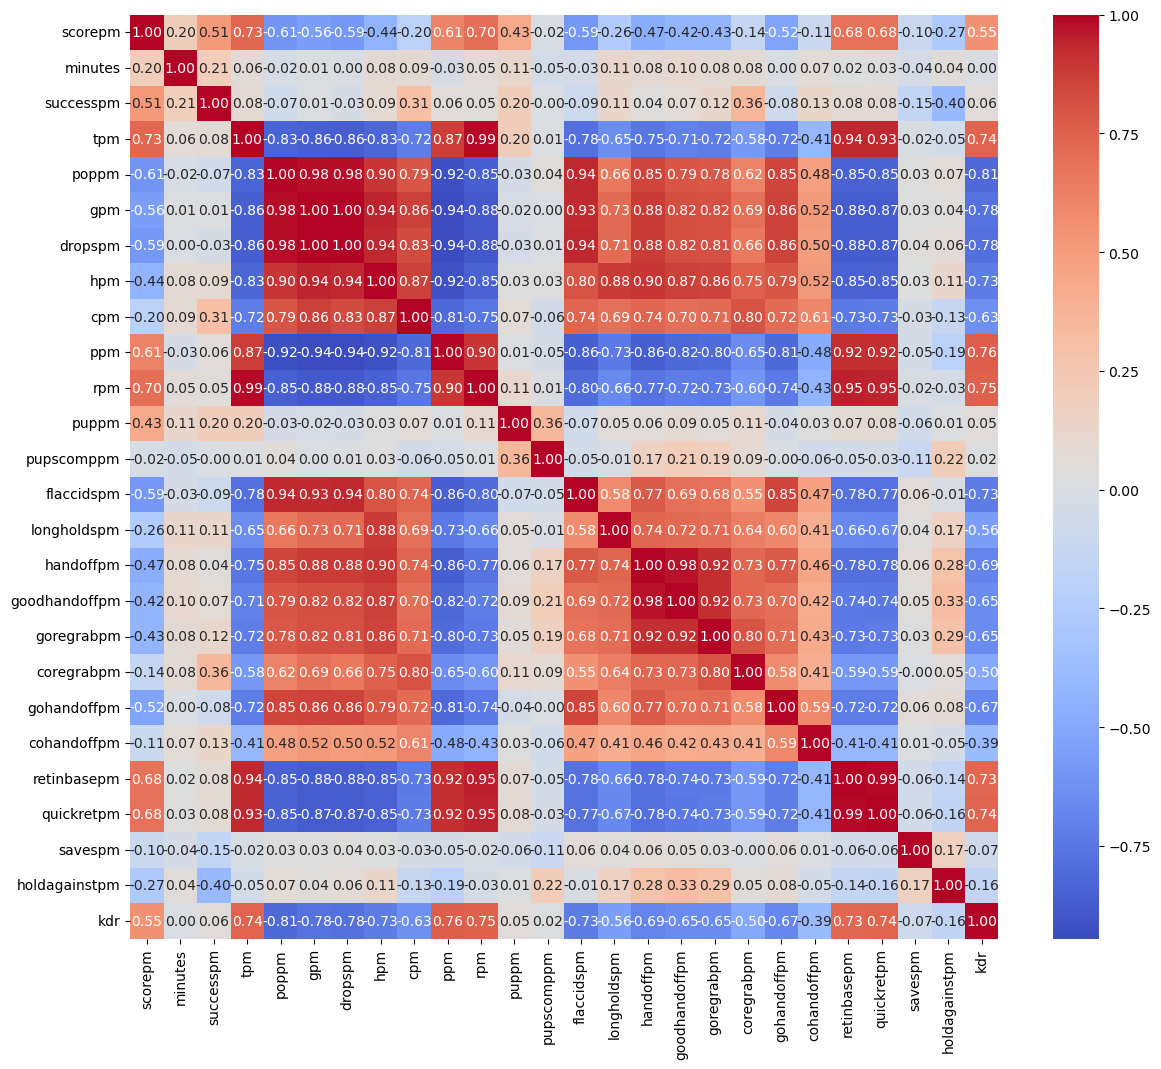

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix = MLTP_master_stats.corr(numeric_only = True)
plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

Clearly there are several groups of highly correlated features, but this isn't inherently an issue depending on what kind of supervised learning method we use going forward. Let's check for collinearity as well while we're at it.

In [34]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select only the numeric features
numeric_cols = MLTP_master_stats.select_dtypes(include=['int64', 'float64']).columns
numeric_cols = numeric_cols.delete(numeric_cols.get_loc('successpm'))

print(numeric_cols)

# Create a DataFrame to store the VIF values
MLTP_vif = pd.DataFrame(columns = ['feature', 'VIF'])

# Calculate the VIF for each feature and insert into VIF df
for i, col in enumerate(numeric_cols):
    vif = variance_inflation_factor(MLTP_master_stats[numeric_cols].values, i)
    MLTP_vif.loc[i] = [col, vif]

# View the VIF DataFrame
print(MLTP_vif)

Index(['scorepm', 'minutes', 'tpm', 'poppm', 'gpm', 'dropspm', 'hpm', 'cpm',
       'ppm', 'rpm', 'puppm', 'pupscomppm', 'flaccidspm', 'longholdspm',
       'handoffpm', 'goodhandoffpm', 'goregrabpm', 'coregrabpm', 'gohandoffpm',
       'cohandoffpm', 'retinbasepm', 'quickretpm', 'savespm', 'holdagainstpm',
       'kdr'],
      dtype='object')
          feature           VIF
0         scorepm    462.833690
1         minutes     16.588393
2             tpm    679.517552
3           poppm    643.470075
4             gpm  29714.256864
5         dropspm  25358.624904
6             hpm    600.696586
7             cpm    296.906290
8             ppm     55.022680
9             rpm    555.049272
10          puppm     53.515205
11     pupscomppm    203.282198
12     flaccidspm    110.875213
13    longholdspm     47.417677
14      handoffpm    196.587234
15  goodhandoffpm    143.605007
16     goregrabpm     51.523165
17     coregrabpm     16.206071
18    gohandoffpm     25.498981
19    cohandof

Most of the features have a Variance Inflation Factor significantly higher than 5, which is the standard cutoff for excluded features from multilinear regression. If only a few had a high VIF, we could prune those out and use linear modeling methodologies but that is untenable in a situation where only two of the features have a VIF < 5. We will need to use a nonlinear modeling approach that is robust against highly correlated and collinear data. 

Modeling

As stated earlier, we need a something that can effectively handle highly correlated features and collinearity. XGBoost and Random Forest would both be strong exemplars of these traits. XGBoost thrives for large amounts of training data and is particularly effective at dealing with imbalanced observations in the size of the classes in the response variable, neither of which is present in our dataset. Random Forest can handle our mixed numerical and categorical features easily without requiring one hot encoding, help us with feature selection, and provides a highly interpretable model, which is critical in allowing the model to provide actionable results to the competitive scene. This points us towards starting out with Random Forest and potentially pivoting to another option if there are serious concerns with the model performance.

First, we will need to separate our master dataframe into our vector of features, X, and our target variable, y. Then, we will split both X and y into the training set that will be used to train the random forest model and the test set that will be used to evaulate our model performance.

In [35]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# Segment main df into features and response
X = MLTP_master_stats.drop(['winner', 'player', 'successpm'], axis = 1)
y = MLTP_master_stats['winner']

# Split into training (85%) and test (15%) sets
X_train_MLTP, X_test_MLTP, y_train_MLTP, y_test_MLTP = train_test_split(X, y, test_size=0.25, random_state = 1234)

# Print the shape of the train and test sets for response and predictors
print("X Train set shape:", X_train_MLTP.shape)
print("X Test set shape:", X_test_MLTP.shape)
print("X Train set shape:", y_train_MLTP.shape)
print("X Test set shape:", y_test_MLTP.shape)

X Train set shape: (702, 28)
X Test set shape: (234, 28)
X Train set shape: (702,)
X Test set shape: (234,)


Next, we will fit a random forest model using RandomForestClassifier with default values and our favorite random state seed for reproducibility purposes. Then we subsequently fit our uneducated model with our training data so that it may partake in glorious supervised learning.

In [36]:
# Create random forest model and fit it to the training data
rf = RandomForestClassifier(n_estimators = 100, random_state = 1234)
rf.fit(X_train_MLTP, y_train_MLTP)

y_pred = rf.predict(X_test_MLTP)

To see how well our base Random Forest model has learned to predict whether or not a North American TagPro majors player had a winning season, let's employ some of the gold standard evaluation metrics for supervised classification tasks like our random forest. Accuracy is a measure of the total correctness of the model, as it is a ratio of true outcomes to total outcomes. Precision is a measure of the predictive power of the model, or 'how many retrieved items were relevant', as it measures the true positives divided by all positives. Sensitivity/recall is the 'fraction of relevant instances that were retrieved', as it measures the true positives divided by the true positives and false negatives. F1 score is a robust evaluation metric, as it is the harmonic mean of both precision and recall, and thus strikes a healthy balance between the two. Choosing which metric is the most important to maximize depends heavily on the task at hand; for predicting winningness of a player we are fairly agnostic on which statistic matters the most, so let's just pick F1 score as it is the best all-rounder.

In [37]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test_MLTP, y_pred)
precision = precision_score(y_test_MLTP, y_pred)
recall = recall_score(y_test_MLTP, y_pred)
f1 = f1_score(y_test_MLTP, y_pred)

# Print the evaluation metrics
print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 score: {f1}")

Accuracy: 0.7008547008547008
Precision: 0.6964285714285714
Recall: 0.6842105263157895
F1 score: 0.6902654867256636


Interestingly, all four of these metrics scored about the same, around 70%, which is quite a solid performance but nothing to write home about. Let's visualize the importance that our model has learned to place on each of our predictor variables:

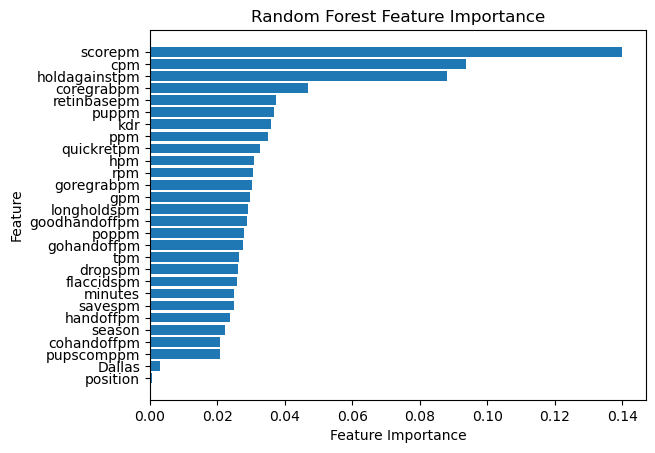

In [38]:
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': rf.feature_importances_})
feature_importance = feature_importance.sort_values(by = 'Importance', ascending = True)

# Create horizontal bar plot of feature importance
plt.barh(feature_importance['Feature'], feature_importance['Importance'])
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Random Forest Feature Importance')
plt.show()

Score was considered to be the most important by a long shot, while caps and hold against were a distant second and third most important. After those three features, there is a significant dropoff in feature importance. If we were going to construct a more parsimonious model from scratch, we could consider using just 'scorepm', 'cpm', and 'holdagainstpm' as our only three features as a solid starting point, and add more in from there if necessary. 

Instead, let's use a grid search technique combined with cross validation to tune our hyperparameters to higher performing values. We can use these parameters to help reduce overfitting and provide some modicom of regularization through limitation of max depth.

In [39]:
from sklearn.model_selection import GridSearchCV

rf_tuner = RandomForestClassifier(random_state = 1234)

# Define the hyperparameter grid
param_grid = {
    'n_estimators': [100, 200, 300, 400, 500],
    'max_depth': [5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Create the GridSearchCV object
grid_search = GridSearchCV(estimator = rf_tuner, param_grid = param_grid, cv = 5)

# Fit the GridSearchCV object to the training data
grid_search.fit(X_train_MLTP, y_train_MLTP)

# Print the best hyperparameters
print("Best parameters: ", grid_search.best_params_)

Best parameters:  {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 400}


We have our list of best hyperparameters as a result of the tuning grid search, so we can fit a new RF model with these specific hyperparameters and see if there is some improvement over our original model.

In [40]:
# Fit training data to new RF model
best_rf = RandomForestClassifier(max_depth = 10, min_samples_leaf = 4, min_samples_split = 2, n_estimators = 400, random_state = 1234)
best_rf.fit(X_train_MLTP, y_train_MLTP)

y_pred_best = best_rf.predict(X_test_MLTP)

#Eval metrics
best_accuracy = accuracy_score(y_test_MLTP, y_pred_best)
best_precision = precision_score(y_test_MLTP, y_pred_best)
best_recall = recall_score(y_test_MLTP, y_pred_best)
best_f1 = f1_score(y_test_MLTP, y_pred_best)

# Print the evaluation metrics
print(f"Accuracy: {best_accuracy}")
print(f"Precision: {best_precision}")
print(f"Recall: {best_recall}")
print(f"F1 score: {best_f1}")

Accuracy: 0.6965811965811965
Precision: 0.7009345794392523
Recall: 0.6578947368421053
F1 score: 0.6787330316742081


Surprisingly, our evaluation metrics for these 'best' hyperparameters came out slightly worse than our original model. This is indicative that our original model was actually quite good with the default hyperparameters, or that our grid search was too narrow. Since the parameter grid we used to search was reasonably wide across each hyperparameter, it seems likely that the first model with default values was simply a fortuitous choice. Let's take a look at the feature importance chart for our tuned model and look for additional insights.

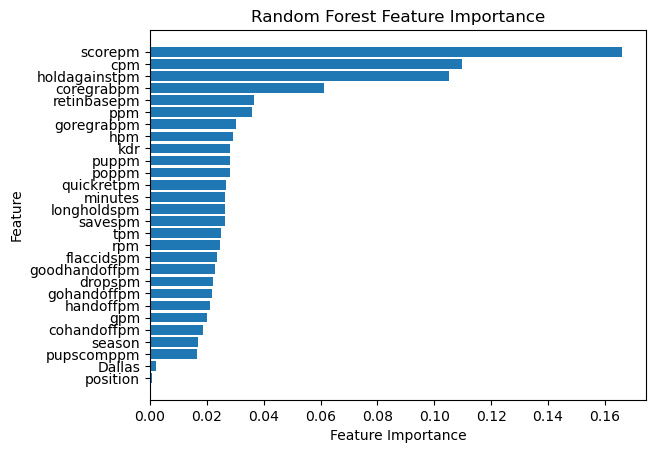

In [41]:
# Match up columns with importance values
feature_importance = pd.DataFrame({'Feature': X_train_MLTP.columns, 'Importance': best_rf.feature_importances_})
feature_importance = feature_importance.sort_values(by = 'Importance', ascending = True)

# Create horizontal bar plot of feature importance
plt.barh(feature_importance['Feature'], feature_importance['Importance'])
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Random Forest Feature Importance')
plt.show()

The top three variables are unchanged from our initial model, but the tuned model seems to place a higher importance on 'coregrabpm' than our first model did. Overall, this model doesn't seem that much different than our first one, so let's try adding in something new. Cost complexity pruning, or CCP, is a technique that can be employed to limit the size of a tree and prevent overfitting. This is another example of a method by which we may perform regularization on a random forest model. CCP is denoted by alpha and the higher the value of alpha, the greater the number of pruned nodes from the tree. Basically, CCP penalizes trees for being overly complicated without sufficient performance justification, so it strikes a balance between accuracy and complexity. We will start off with our preferred hyperparameters from our tuned model and search for our optimal value of alpha for CCP.

Text(0.5, 1.0, 'Total Impurity vs Alpha')

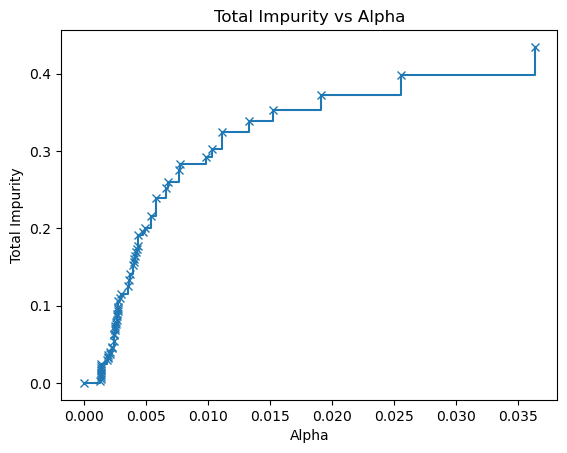

In [42]:
from sklearn.tree import DecisionTreeClassifier

# Store the best hyperparameters for the random forest from previous grid search
best_params = grid_search.best_params_

# Create the decision tree and apply cost complexity pruning
clf = DecisionTreeClassifier(random_state = 1234)
path = clf.cost_complexity_pruning_path(X_train_MLTP, y_train_MLTP)
alphas, impurities = path.ccp_alphas, path.impurities
clfs = []

#Impurity vs alpha graph
fig, ax = plt.subplots()
ax.plot(alphas[:-1], impurities[:-1], marker="x", drawstyle="steps-post")
ax.set_xlabel("Alpha")
ax.set_ylabel("Total Impurity")
ax.set_title("Total Impurity vs Alpha")

Now we train a random forest model on on training set for each of our values of alpha to find the highest performing model.

In [43]:
# Train many RF models
for alpha in alphas:
    clf = DecisionTreeClassifier(random_state = 1234, ccp_alpha = alpha)
    clf.fit(X_train_MLTP, y_train_MLTP)
    clfs.append(clf)

# Find the optimal value for ccp_alpha
scores = [accuracy_score(y_test_MLTP, clf.predict(X_test_MLTP)) for clf in clfs]
best_alpha = alphas[np.argmax(scores)]

# Create the final decision tree with the optimal alpha value
final_clf = DecisionTreeClassifier(random_state = 42, ccp_alpha = best_alpha)
final_clf.fit(X_train_MLTP, y_train_MLTP)
print(best_alpha)

[0.30081999 0.01573848 0.         0.04243079 0.02900372 0.
 0.         0.12284226 0.02672407 0.07212417 0.01910213 0.
 0.         0.03556387 0.01057399 0.         0.04620052 0.02862688
 0.         0.05121527 0.00925224 0.01057399 0.         0.15332703
 0.         0.         0.02588059 0.        ]
[ 0  1  3  4  7  8  9 10 13 14 16 17 19 20 21 23 26]
(702, 28)
Index(['scorepm', 'minutes', 'poppm', 'gpm', 'cpm', 'ppm', 'rpm', 'puppm',
       'longholdspm', 'handoffpm', 'goregrabpm', 'coregrabpm', 'cohandoffpm',
       'retinbasepm', 'quickretpm', 'holdagainstpm', 'kdr'],
      dtype='object')
Accuracy: 0.6794871794871795
Precision: 0.6756756756756757
Recall: 0.6578947368421053
F1 score: 0.6666666666666667


Next, we can remove features that were not deemed to be important enough by the cost complexity pruning to keep in our model and go through the model training and fitting process once again:

In [ ]:
# Use the pruned decision tree as a feature selector for the random forest
feature_importances = final_clf.feature_importances_
print(feature_importances)
important_features = np.where(feature_importances > 0)[0]
print(important_features)
print(X_train_MLTP.shape)

# Remove columns with insufficient importance
X_train_pruned = X_train_MLTP.iloc[:, important_features]
X_test_pruned = X_test_MLTP.iloc[:, important_features]

pruned_cols = X_train_pruned.columns
print(pruned_cols)

# Fit pruned model
rf_pruned = RandomForestClassifier(**best_params, random_state = 1234)
rf_pruned.fit(X_train_pruned, y_train_MLTP)

y_pred_pruned = rf_pruned.predict(X_test_pruned)

# Classification metrics
pruned_accuracy = accuracy_score(y_test_MLTP, y_pred_pruned)
pruned_precision = precision_score(y_test_MLTP, y_pred_pruned)
pruned_recall = recall_score(y_test_MLTP, y_pred_pruned)
pruned_f1 = f1_score(y_test_MLTP, y_pred_pruned)

# Print the evaluation metrics
print(f"Accuracy: {pruned_accuracy}")
print(f"Precision: {pruned_precision}")
print(f"Recall: {pruned_recall}")
print(f"F1 score: {pruned_f1}")

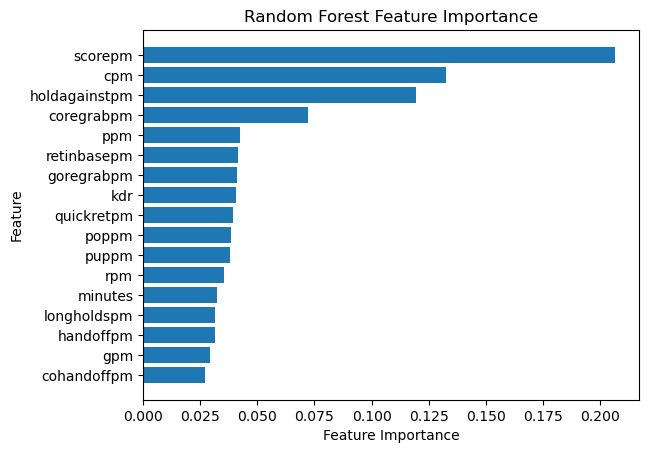

In [44]:
feature_importance = pd.DataFrame({'Feature': X_train_pruned.columns, 'Importance': rf_pruned.feature_importances_})
feature_importance = feature_importance.sort_values(by = 'Importance', ascending = True)

# Create horizontal bar plot of feature importance
plt.barh(feature_importance['Feature'], feature_importance['Importance'])
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Random Forest Feature Importance')
plt.show()

Discussion and Conclusion

Unfortunately, we once again have a model that places relatively similar importance and weights on each of the included features, and also scores approximately the same across the supervised learning classification evaulation metrics. Due to the similarity between all of the models, we could select the original model as our winner considering it has the highest evaluation metrics scores and it also required very little effort to run with default hyperparameters. A case could also be made that since our pruned model only performed slightly worse while only using 17 features instead of 28, the parsimoniousness of the model outweighs the small performance decrease. The author will side with the pruned model due to the aforementioned reasons (and selfishly because the model feels more special as a labor of love than as the default options given by scikit learn).

Interestingly, the random forest models and the player evaluation metrics used the by the TagPro community only agreed on one variable being very important, which was captures per minute. Besides that golden connector between the two groups, the random forest model was an enjoyer of score, hold against, and caps off of regrab, while the community places more value on tags, hold, grabs, powerups, and prevent. More investigation will definitely be required to fully flesh out the ramifications of these initial findings, but it does suggest that there may need to be a shift in how pro players are approaching the game.

In retrospect, it was potentially a foolhardly endeavor to try to include position, and to a lesser extent, server as innate features. Much more prudent would have been to segment the dataset into at least two but possibly four total datasets, bucketed by either position or position and server. The models may have struggled to extract meaningful conclusions by treating all players as a single population, when it makes more sense to treat defenders and offenders as totally separate populations of players and build distinct models for each, instead of having the populations pulling the random forest's decision making in different directions. 

Another possible way to improve the modeling process would be to gather more data to create a much larger set to work with, giving a better opportunity for data intensive techniques like XGBoost to possibly offer a hike in performance. Instead of sampling from just NA majors players, other regions and lower level leagues could have been incorporated to make a more robust dataset for the algorithms to learn from.